# BÁO CÁO TOÀN DIỆN VÀ GIẢI TRÌNH MÃ NGUỒN DỰ ÁN (ADY201m - NHÓM 6)
### Đề tài: Cào dữ liệu, Quản lý CSDL SQL Server, Phân tích EDA và Xây dựng mô hình AI Phân loại tin tức VnExpress

---

## MỤC LỤC TỔNG QUAN
1. **Kiến trúc luồng xử lý dữ liệu và Phương pháp luận Data Science John Rollins**
2. **Phase 1: Thu thập và Tiền xử lý dữ liệu (Web Crawler & Post-processing)**
   - `Step1_RawCrawler.py`: Thu thập bài viết thô từ 16 RSS feeds
   - `Step2_DataFilter.py`: Bộ lọc sàng lọc chất lượng bài viết
3. **Phase 2: Lưu trữ, Khử trùng lặp và Truy vấn trên CSDL SQL Server**
   - `SQLschema.sql`: Lược đồ CSDL, cấu trúc bảng `dbo.VnExpress_Articles` và Index
   - `SQLimporter.py`: Nạp dữ liệu vào SQL Server, kiểm tra kết nối, khử trùng 2 lớp và Bulk Insert
4. **Phase 3: Phân tích Khám phá Dữ liệu (EDA) & Trực quan hóa Biểu đồ**
   - Nạp dữ liệu SQL và tiền xử lý chỉ số thống kê
   - **Biểu đồ 1:** Số bài theo chuyên mục (`bieu_do_1_chuyen_muc.png`)
   - **Biểu đồ 2:** Tần số xuất bản theo 24 khung giờ & Phân tích hiện tượng đỉnh 0h (`bieu_do_2_phan_bo_gio.png`)
   - **Biểu đồ 3:** Cơ cấu tác giả bài viết (`bieu_do_3_tac_gia.png`)
   - **Biểu đồ 4:** Bản đồ nhiệt mật độ bài viết ma trận lịch tháng (`bieu_do_4_nhiet_do_thang.png`)
5. **Phase 4: Huấn luyện và Đánh giá Mô hình AI Phân loại (`TrainClassifier.py`)**
   - Tiền xử lý ngôn ngữ tự nhiên (NLP) tiếng Việt
   - Trích xuất đặc trưng văn bản bằng TF-IDF
   - Huấn luyện mô hình Cây quyết định (Decision Tree) & Naive Bayes
   - **Đánh giá chẩn đoán và Ma trận nhầm lẫn (`confusion_matrix.png`)**
   - Trích xuất đặc trưng quan trọng (Feature Importance)
   - Hàm phụ trợ dự đoán tức thì cho bài báo mới
6. **Phase 5: Vận hành Tự động hóa Pipeline (`Automation.py`)**
   - Điều phối tuần tự 5 bước theo chu trình khép kín hoàn chỉnh của dự án


---
# PHẦN 1: THU THẬP VÀ TIỀN XỬ LÝ DỮ LIỆU (PHASE 1)

## 1.1. Cào dữ liệu thô từ 16 RSS Feeds (`Step1_RawCrawler.py`)

### Mục tiêu thiết kế
- Quét các kênh RSS chuẩn của **16 chuyên mục chính thống** trên VnExpress.
- Thu thập bài viết trong vòng **7 ngày gần nhất** (`CRAWL_DAYS = 7`).
- Bóc tách đầy đủ 9 trường dữ liệu và lưu trữ độc lập vào tệp tin JSON thô `vnexpress_raw.json`.
- Thiết lập độ trễ an toàn `REQUEST_DELAY = 0.5s` và `TIMEOUT = 12s` để chống bị chặn kết nối HTTP 429.


In [ ]:
import os
import re
import sys
import time
import json
from datetime import datetime, timedelta
from email.utils import parsedate_to_datetime
import requests
from bs4 import BeautifulSoup

if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")

REQUEST_DELAY = 0.5
TIMEOUT = 12
CRAWL_DAYS = 7

CATEGORIES = [
    "thoi-su", "the-gioi", "kinh-doanh", "bat-dong-san", "khoa-hoc-cong-nghe",
    "giai-tri", "the-thao", "phap-luat", "giao-duc", "suc-khoe", "doi-song",
    "du-lich", "oto-xe-may", "tam-su", "y-kien", "thu-gian"
]


### Giải thích chi tiết các hàm trong `Step1_RawCrawler.py`

#### 1. Hàm `fetch(url)`
- **Nhiệm vụ:** Gửi yêu cầu HTTP GET có kèm Header giả lập trình duyệt Chrome (`User-Agent`) và `Accept-Language` tiếng Việt.
- **Xử lý ngoại lệ:** Dùng `res.raise_for_status()` để phát hiện lỗi HTTP; nếu có lỗi mạng sẽ trả về chuỗi rỗng `""` thay vì làm gián đoạn chương trình.


In [ ]:
# Tải mã nguồn HTML của URL với cấu hình User-Agent, timeout và độ trễ ngắt quãng
def fetch(url):
    time.sleep(REQUEST_DELAY)
    try:
        res = requests.get(url, headers=HEADERS, timeout=TIMEOUT)
        res.raise_for_status()
        res.encoding = "utf-8"
        return res.text
    except requests.RequestException:
        return ""


#### 2. Hàm `normalize_datetime(raw)`
- **Nhiệm vụ:** Chuẩn hóa chuỗi thời gian xuất bản thô sang định dạng chuẩn quốc tế `YYYY-MM-DD HH:MM:SS`.
- **Cơ chế:** Sử dụng biểu thức chính quy (Regex) để nhận diện hai mẫu định dạng phổ biến trên báo:
  1. Định dạng ISO: `YYYY-MM-DD[T ]HH:MM`
  2. Định dạng ngày tháng Việt Nam: `DD/MM/YYYY` kèm giờ `HH:MM`. Nếu bài viết không ghi rõ giờ, hệ thống sẽ gán mặc định `00:00:00`.


In [ ]:
# Chuẩn hóa chuỗi thời gian xuất bản thô sang định dạng chuẩn 'YYYY-MM-DD HH:MM:SS'
def normalize_datetime(raw):
    if not raw:
        return None
    iso = re.search(r"\d{4}-\d{2}-\d{2}[ T]\d{2}:\d{2}", raw)
    if iso:
        return datetime.strptime(iso.group(0).replace("T", " "), "%Y-%m-%d %H:%M").strftime("%Y-%m-%d %H:%M:%S")

    dm = re.search(r"\d{1,2}/\d{1,2}/\d{4}", raw)
    tm = re.search(r"\d{1,2}:\d{2}", raw)
    if dm:
        dt = datetime.strptime(dm.group(0), "%d/%m/%Y")
        if tm:
            h, m = map(int, tm.group(0).split(":"))
            dt = dt.replace(hour=h, minute=m)
        return dt.strftime("%Y-%m-%d %H:%M:%S")
    return None


#### 3. Hàm `extract_raw_article(html, url, fallback_date, default_category)`
- **Nhiệm vụ:** Sử dụng `BeautifulSoup` để bóc tách 9 trường thông tin chi tiết:
  - `article_id`: Mã định danh lấy từ thẻ meta `tt_article_id` hoặc chuỗi số cuối link.
  - `og_type`: Nhận diện loại trang (bài báo văn bản `article`, trang ảnh `photo`, trang `video`).
  - `title`, `description`, `content`: Tiêu đề, phần mở đầu sapo và toàn bộ nội dung ghép từ các thẻ `<p>`.
  - `category`, `subcategory`: Lấy từ thanh điều hướng breadcrumb (`ul.breadcrumb li a`).


In [ ]:
# Bóc tách 9 trường dữ liệu bài viết từ HTML của trang bài báo VnExpress
def extract_raw_article(html, url, fallback_date=None, default_category="Khác"):
    if not html:
        return None

    soup = BeautifulSoup(html, "html.parser")
    og = soup.find("meta", {"property": "og:type"})
    og_type = og.get("content", "").lower() if og else "unknown"

    date_tag = soup.find("span", class_="date")
    raw_date = date_tag.text.strip() if date_tag else ""
    if not raw_date:
        m_date = soup.find("meta", {"name": "pubdate"})
        raw_date = m_date.get("content", "").strip() if m_date else ""
    published_at = normalize_datetime(raw_date) or fallback_date

    h1 = soup.find("h1", class_="title-detail") or soup.find("h1")
    title = h1.text.strip() if h1 else ""

    desc_tag = soup.find("p", class_="description")
    description = desc_tag.text.strip() if desc_tag else ""
    if not description:
        m_desc = soup.find("meta", {"name": "description"}) or soup.find("meta", {"property": "og:description"})
        description = m_desc.get("content", "").strip() if m_desc else ""

    crumbs = [
        a.text.strip() for a in soup.select("ul.breadcrumb li a")
        if a.text.strip().lower() not in ["", "trang chủ"]
    ]
    category = crumbs[0] if crumbs else default_category
    subcategory = crumbs[1] if len(crumbs) > 1 else "Không có"

    paragraphs = [
        p.text.strip() for p in soup.select(".fck_detail p.Normal, .fck_detail p, article p")
        if p.text.strip()
    ]
    content = "\n".join(paragraphs)

    meta_id = soup.find("meta", {"name": "tt_article_id"})
    aid = meta_id["content"] if meta_id and meta_id.get("content") else url.split("?")[0].split("-")[-1].replace(".html", "")

    return {
        "article_id": aid,
        "title": title,
        "description": description,
        "content": content,
        "author": "VnExpress",
        "published_at": published_at,
        "category": category,
        "subcategory": subcategory,
        "url": url,
        "og_type": og_type,
        "raw_word_count": len(content.split()),
        "crawled_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    }


#### 4. Hàm `collect_all_rss_links()` - Quét và lọc liên kết RSS
- **Mục tiêu:** Quét danh sách liên kết từ 16 chuyên mục RSS của VnExpress trong giới hạn `CRAWL_DAYS = 7` ngày.
- **Xử lý thời gian:** Dùng `parsedate_to_datetime()` để giải mã thẻ `<pubDate>` từ chuẩn RFC 2822 sang giờ địa phương và đối chiếu với mốc `cutoff_dt`.
- **Kết quả:** Trả về dictionary ánh xạ `{url: (pub_str, category)}` đã lọc trùng liên kết.


In [ ]:
# Quét danh sách các liên kết RSS của 16 chuyên mục trong 7 ngày gần nhất
def collect_all_rss_links():
    print("[*] Quét toàn bộ RSS feeds của 16 chuyên mục VnExpress...")
    cutoff_dt = datetime.now() - timedelta(days=CRAWL_DAYS)
    urls = {}
    for cat in CATEGORIES:
        xml = fetch(f"https://vnexpress.net/rss/{cat}.rss")
        if not xml:
            continue
        try:
            soup = BeautifulSoup(xml, "xml")
            for item in soup.find_all("item"):
                link_tag = item.find("link")
                link = link_tag.text.strip() if link_tag else ""
                if not link or not link.endswith(".html"):
                    continue

                pub_tag = item.find("pubDate")
                pub_str = None
                is_within_days = True
                if pub_tag and pub_tag.text:
                    try:
                        dt = parsedate_to_datetime(pub_tag.text.strip()).astimezone().replace(tzinfo=None)
                        pub_str = dt.strftime("%Y-%m-%d %H:%M:%S")
                        if dt < cutoff_dt:
                            is_within_days = False
                    except Exception:
                        pass

                if not is_within_days:
                    continue

                clean_url = link.split("?")[0]
                if clean_url not in urls:
                    urls[clean_url] = (pub_str, cat)
        except Exception:
            pass

    print(f"[+] Tổng số liên kết độc nhất tìm thấy: {len(urls)} links.")
    return urls


#### 5. Hàm `main()` trong `Step1_RawCrawler.py` - Điều phối tiến trình cào thô
- **Quy trình:** Nhận danh sách URL từ `collect_all_rss_links()`, duyệt cào từng bài viết bằng `fetch()`, bóc tách bằng `extract_raw_article()` và xuất toàn bộ kết quả ra tệp tin JSON thô `vnexpress_raw.json`.


In [ ]:
# Cào toàn bộ bài viết từ RSS và lưu trữ vào tệp json vnexpress_raw.json
def main():
    links_dict = collect_all_rss_links()
    print("-> Đang cào dữ liệu...")

    raw_articles = []
    for url, (pub_date, cat) in links_dict.items():
        html = fetch(url)
        art = extract_raw_article(html, url, pub_date, cat)
        if art:
            raw_articles.append(art)

    with open(RAW_OUTPUT_PATH, "w", encoding="utf-8") as f:
        json.dump(raw_articles, f, ensure_ascii=False, indent=2)

    print(f"-> Đã cào xong {len(raw_articles)} bài!")
    rel_raw = os.path.relpath(RAW_OUTPUT_PATH, PROJECT_DIR)
    print(f"[+] Đã lưu tại: {rel_raw}")


---
## 1.2. Sàng lọc và Tiền xử lý dữ liệu (`Step2_DataFilter.py`)

### Mục tiêu và Tiêu chí loại bỏ bài viết kém chất lượng
Tệp thô `vnexpress_raw.json` được đưa qua bộ lọc kiểm định chất lượng nghiêm ngặt trước khi nạp vào CSDL SQL Server:
1. **Thiếu tiêu đề:** Loại bỏ bài có `title` rỗng.
2. **Không phải bài báo văn bản:** Loại bỏ các trang có `og_type` khác `article` (như trang video, phóng sự ảnh tĩnh).
3. **Nội dung quá ngắn:** Loại bỏ bài có số từ `< 50 từ` (`MIN_WORD_COUNT = 50`) để tránh bài thử nghiệm hoặc trang lỗi.
4. **Ngoài phạm vi thời gian:** Loại bỏ bài xuất bản trước mốc `FILTER_DAYS = 7` ngày.
5. **Báo cáo kiểm toán:** Ghi nhận và thống kê chi tiết số lượng bài bị loại theo từng lý do cụ thể.


### Hàm 1: `load_raw_dataset()` - Nạp dữ liệu bài viết thô
- **Mục tiêu:** Quét danh sách các đường dẫn ứng viên `RAW_CANDIDATES` để tìm và nạp tệp `vnexpress_raw.json` an toàn.


In [ ]:
# Nạp tập dữ liệu bài viết thô (JSON) từ các thư mục ứng viên khả dĩ
def load_raw_dataset():
    for path in RAW_CANDIDATES:
        if os.path.exists(path):
            with open(path, "r", encoding="utf-8-sig") as f:
                data = json.load(f)
            rel_path = os.path.relpath(path, PROJECT_DIR)
            print(f"[*] Nạp thành công {len(data)} bài viết thô từ: {rel_path}")
            return data
    raise FileNotFoundError("Chưa tìm thấy tệp dữ liệu thô 'vnexpress_raw.json'. Hãy chạy Step1_RawCrawler.py trước.")


### Hàm 2: `filter_articles(raw_articles)` - Thực thi sàng lọc chất lượng
- **Mục tiêu:** Duyệt qua từng bản ghi, kiểm tra tiêu đề, loại tài nguyên `og_type`, số lượng từ và mốc thời gian xuất bản.
- **Thống kê kiểm toán:** Tổng hợp số bài bị loại vào từ điển `reason_stats` và sắp xếp danh sách bài hợp lệ theo thời gian mới nhất lên đầu.


In [ ]:
# Sàng lọc bài viết theo chất lượng: bắt buộc có tiêu đề, đúng định dạng bài báo văn bản, đủ độ dài và trong 7 ngày
def filter_articles(raw_articles):
    cutoff_datetime = datetime.now() - timedelta(days=FILTER_DAYS)
    cutoff_str = cutoff_datetime.strftime("%Y-%m-%d %H:%M:%S")
    valid_articles = []
    reason_stats = {}

    for art in raw_articles:
        title = art.get("title", "").strip()
        content = art.get("content", "").strip()
        pub_str = art.get("published_at")
        og_type = art.get("og_type", "article")

        if not title:
            reason = "Thiếu tiêu đề"
            reason_stats[reason] = reason_stats.get(reason, 0) + 1
            continue

        if og_type not in ["article", "unknown", ""]:
            reason = f"Không phải bài báo văn bản (ex:type = {og_type})"
            reason_stats[reason] = reason_stats.get(reason, 0) + 1
            continue

        words = len(content.split())
        if words < MIN_WORD_COUNT:
            reason = f"Nội dung quá ngắn (< ngưỡng {MIN_WORD_COUNT} từ)"
            reason_stats[reason] = reason_stats.get(reason, 0) + 1
            continue

        if pub_str:
            try:
                if datetime.strptime(pub_str, "%Y-%m-%d %H:%M:%S") < cutoff_datetime:
                    reason = f"Ngoài phạm vi {FILTER_DAYS} ngày gần nhất ({cutoff_str})"
                    reason_stats[reason] = reason_stats.get(reason, 0) + 1
                    continue
            except Exception:
                pass

        valid_articles.append({
            "article_id": art.get("article_id", "N/A"),
            "title": title,
            "description": art.get("description", "").strip(),
            "content": content,
            "author": "VnExpress",
            "published_at": pub_str,
            "category": art.get("category", "Khác"),
            "subcategory": art.get("subcategory", "Không có"),
            "url": art.get("url", ""),
        })

    valid_articles.sort(key=lambda x: str(x.get("published_at", "")), reverse=True)
    return valid_articles, reason_stats


### Hàm 3: `main()` trong `Step2_DataFilter.py` - Lưu trữ tệp sạch và In báo cáo
- **Quy trình:** Nạp tệp thô qua `load_raw_dataset()`, thực thi `filter_articles()`, ghi kết quả đạt chuẩn vào `vnexpress_data.json` và in bảng chi tiết các nguyên nhân loại bỏ ra màn hình.


In [ ]:
# Lọc sạch dữ liệu bài viết thô, xuất ra file vnexpress_data.json và in thống kê
def main():
    raw_data = load_raw_dataset()
    valid_articles, reason_stats = filter_articles(raw_data)

    for out_path in FILTERED_OUTPUT_PATHS:
        os.makedirs(os.path.dirname(out_path), exist_ok=True)
        with open(out_path, "w", encoding="utf-8") as f:
            json.dump(valid_articles, f, ensure_ascii=False, indent=2)

    rejected_count = len(raw_data) - len(valid_articles)
    print(f"[+] Tổng số bài đầu vào thô:  {len(raw_data)} bài")
    print(f"[+] Số bài đạt chuẩn giữ lại: {len(valid_articles)} bài")
    print(f"[+] Số bài bị loại bỏ:        {rejected_count} bài")

    rel_out = os.path.relpath(FILTERED_OUTPUT_PATHS[0], PROJECT_DIR)
    print(f"[+] Đã lưu tại: {rel_out}")

    if reason_stats:
        print("[+] Chi tiết nguyên nhân loại bỏ bài viết:")
        for reason, count in sorted(reason_stats.items(), key=lambda x: x[1], reverse=True):
            print(f"  - {reason:<45}: {count:3d} bài")


---
# PHẦN 2: LƯU TRỮ VÀ TÍCH HỢP CSDL QUAN HỆ (PHASE 2)

## 2.1. Lược đồ Cơ sở Dữ liệu (`SQLschema.sql`)

### Thiết kế bảng `dbo.VnExpress_Articles`
Bảng dữ liệu được thiết kế trên hệ quản trị Microsoft SQL Server (`Database: ADY201m`) nhằm đảm bảo tính toàn vẹn dữ liệu và tối ưu hóa truy vấn:
- **`article_id NVARCHAR(50)` (PRIMARY KEY):** Đảm bảo tính duy nhất tuyệt đối của từng bài viết, chống ghi đè hoặc trùng lặp dữ liệu khi chạy cào định kỳ.
- **`title NVARCHAR(1000)`:** Lưu tiêu đề tiếng Việt có dấu.
- **`description` & `content` (`NVARCHAR(MAX)`):** Hỗ trợ lưu văn bản dài không giới hạn ký tự.
- **`published_at DATETIME`:** Lưu mốc thời gian xuất bản chuẩn hóa để phục vụ truy vấn phân tích theo giờ, ngày, tháng.
- **`created_at DATETIME DEFAULT GETDATE()`:** Ghi nhận thời điểm bản ghi được nạp vào hệ thống CSDL.
- **Chỉ mục (Index) `IX_Articles_Category`:** Tối ưu hóa tốc độ các truy vấn gom nhóm (`GROUP BY category`) trong bước phân tích EDA.


In [ ]:
-- Khởi tạo Database và Bảng lưu trữ bài báo VnExpress
IF NOT EXISTS (SELECT name FROM sys.databases WHERE name = N'ADY201m')
BEGIN
    CREATE DATABASE ADY201m;
END
GO

USE ADY201m;
GO

IF OBJECT_ID(N'dbo.VnExpress_Articles', N'U') IS NULL
BEGIN
    CREATE TABLE dbo.VnExpress_Articles (
        article_id      NVARCHAR(50)   NOT NULL CONSTRAINT PK_VnExpress_Articles PRIMARY KEY,
        title           NVARCHAR(1000) NOT NULL,
        description     NVARCHAR(MAX)  NULL,
        content         NVARCHAR(MAX)  NULL,
        author          NVARCHAR(255)  NULL,
        published_at    DATETIME       NULL,
        category        NVARCHAR(100)  NULL,
        subcategory     NVARCHAR(100)  NULL,
        url             NVARCHAR(1000) NULL,
        created_at      DATETIME       NOT NULL CONSTRAINT DF_Articles_CreatedAt DEFAULT GETDATE()
    );

    -- Tạo Index hỗ trợ truy vấn nhanh theo chuyên mục cho bước EDA
    CREATE INDEX IX_Articles_Category ON dbo.VnExpress_Articles(category);
END
GO


---
## 2.2. Tiến trình Nạp liệu và Khử trùng lặp (`SQLimporter.py`)

### Quy trình nạp dữ liệu an toàn và hiệu năng cao
1. **Kiểm tra an toàn kết nối:** Kiểm tra CSDL `ADY201m` và bảng `dbo.VnExpress_Articles` qua catalog hệ thống `sys.databases` và `OBJECT_ID`.
2. **Khử trùng lặp 2 lớp (Two-tier Deduplication):**
   - *Lớp 1 (Trong batch):* Sử dụng cấu trúc `set()` để loại bỏ ngay các bài trùng mã `article_id` trong cùng một file JSON.
   - *Lớp 2 (So với CSDL):* Truy vấn toàn bộ `article_id` đang có trong bảng `dbo.VnExpress_Articles` (`SELECT article_id FROM dbo.VnExpress_Articles`), lọc ra danh sách bài báo hoàn toàn mới (`new_articles`).
3. **Nạp siêu tốc theo lô (Bulk Insert):**
   - Kích hoạt `cursor.fast_executemany = True` của `pyodbc` để truyền toàn bộ mảng tham số trong một transaction duy nhất, giảm thiểu độ trễ mạng.
   - *Cơ chế phục hồi (Fallback):* Nếu lệnh bulk bị lỗi, hệ thống tự động bắt ngoại lệ và chuyển sang nạp từng dòng đơn lẻ để cô lập bản ghi lỗi mà không hủy bỏ các bản ghi hợp lệ khác.


### Hàm 1: `to_datetime(value)` - Chuyển đổi kiểu ngày giờ SQL
- **Mục tiêu:** Ép chuỗi ngày `'YYYY-MM-DD HH:MM:SS'` từ crawler sang đối tượng `datetime` để ghi hợp lệ vào cột `DATETIME` trong CSDL SQL Server.


In [ ]:
# Chuyển đổi chuỗi ngày giờ 'YYYY-MM-DD HH:MM:SS' sang đối tượng datetime cho SQL DATETIME
def to_datetime(value):
    if not value:
        return None
    try:
        return datetime.strptime(value, "%Y-%m-%d %H:%M:%S")
    except ValueError:
        return None


### Hàm 2: `database_exists()` - Kiểm tra sự tồn tại của Database
- **Mục tiêu:** Mở kết nối tới database hệ thống `master`, truy vấn bảng catalog `sys.databases` để xác nhận CSDL `ADY201m` đã được tạo sẵn sàng.


In [ ]:
# Kiểm tra xem CSDL ADY201m đã tồn tại trên SQL Server hay chưa
def database_exists():
    conn = pyodbc.connect(MASTER_CONN, autocommit=True)
    cursor = conn.cursor()
    cursor.execute("SELECT database_id FROM sys.databases WHERE name = ?", DATABASE)
    found = cursor.fetchone() is not None
    cursor.close()
    conn.close()
    return found


### Hàm 3: `table_exists(cursor)` - Kiểm tra sự tồn tại của Bảng dữ liệu
- **Mục tiêu:** Sử dụng hàm hệ thống `OBJECT_ID(N'dbo.VnExpress_Articles', N'U')` để xác định bảng đã tồn tại trước khi thực hiện thao tác nạp liệu.


In [ ]:
# Kiểm tra xem bảng dbo.VnExpress_Articles đã được tạo trong CSDL hay chưa
def table_exists(cursor):
    cursor.execute("SELECT OBJECT_ID(N'dbo.VnExpress_Articles', N'U')")
    return cursor.fetchone()[0] is not None


### Hàm 4: `import_json_to_sql(json_path)` - Nạp dữ liệu và Khử trùng lặp 2 lớp
- **Mục tiêu:** Đọc tệp JSON sạch, lọc trùng khóa chính ngay trong batch bằng `set()`, đối chiếu với danh sách ID hiện có trong SQL Server, kích hoạt `fast_executemany = True` để nạp siêu tốc và có cơ chế fallback chèn từng dòng nếu gặp sự cố.


In [ ]:
# Đọc file JSON, khử trùng lặp và nạp các bài viết mới vào bảng dbo.VnExpress_Articles
def import_json_to_sql(json_path=None):
    base_dir = os.path.dirname(os.path.abspath(__file__))
    project_dir = os.path.dirname(base_dir)

    default_path = os.path.join(project_dir, "Phase 1 - Data crawl & Post process + Quick report", "vnexpress_data.json")
    path = json_path or (default_path if os.path.exists(default_path) else os.path.join(base_dir, "vnexpress_data.json"))
    if not os.path.exists(path):
        print(f"[!] Không tìm thấy file dữ liệu: {path}")
        return

    rel_path = os.path.relpath(path, project_dir)
    print(f"[+] Đang nạp dữ liệu từ: {rel_path} vào database...")

    with open(path, "r", encoding="utf-8") as f:
        articles = json.load(f)

    if not database_exists():
        print(f"[!] Database '{DATABASE}' chưa tồn tại trên {SERVER}." + SCHEMA_HINT)
        return

    conn = pyodbc.connect(DB_CONN, autocommit=True)
    cursor = conn.cursor()

    if not table_exists(cursor):
        print(f"[!] Bảng 'dbo.VnExpress_Articles' chưa tồn tại trong '{DATABASE}'." + SCHEMA_HINT)
        cursor.close()
        conn.close()
        return

    # Khử trùng lặp Lớp 1 (ngay trong batch JSON)
    seen = set()
    batch_unique = []
    for a in articles:
        aid = a.get("article_id")
        if aid and aid not in seen:
            seen.add(aid)
            batch_unique.append(a)

    # Khử trùng lặp Lớp 2 (đối chiếu với CSDL)
    cursor.execute("SELECT article_id FROM dbo.VnExpress_Articles")
    existing_ids = {row[0] for row in cursor.fetchall()}
    new_articles = [a for a in batch_unique if a["article_id"] not in existing_ids]

    insert_sql = """
    INSERT INTO dbo.VnExpress_Articles
    (article_id, title, description, content, author, published_at, category, subcategory, url)
    VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
    """

    def to_params(a):
        return (
            a.get("article_id"), a.get("title"), a.get("description"),
            a.get("content"), a.get("author"), to_datetime(a.get("published_at")),
            a.get("category"), a.get("subcategory"), a.get("url"),
        )

    inserted, failed = 0, []
    if not new_articles:
        print("[+] Không có bài mới, bỏ qua bước chèn.")
    else:
        try:
            cursor.fast_executemany = True
            cursor.executemany(insert_sql, [to_params(a) for a in new_articles])
            inserted = len(new_articles)
        except pyodbc.Error as bulk_err:
            cursor.fast_executemany = False
            print(f"[!] executemany lỗi ({bulk_err}); chuyển sang chèn từng dòng...")
            for a in new_articles:
                try:
                    cursor.execute(insert_sql, to_params(a))
                    inserted += 1
                except pyodbc.Error as e:
                    failed.append((a.get("article_id"), str(e).strip()))

    cursor.close()
    conn.close()
    skipped = len(articles) - len(new_articles)
    print(f"[+] Đã hoàn thành! Đã thêm mới: {inserted} bài | Bỏ qua trùng lặp: {skipped} bài.")


---
# PHẦN 3: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA) VÀ TRỰC QUAN HÓA (PHASE 3)

## 3.1. Thu thập dữ liệu và Tính toán chỉ số thống kê (`Charts.py`)

### Cơ chế nạp dữ liệu linh hoạt (Database First with Fallback)
Hàm `get_data()` ưu tiên truy vấn dữ liệu trực tiếp từ SQL Server thông qua kết nối `pyodbc`. Nếu SQL Server chưa khởi chạy hoặc chưa hoàn tất nạp liệu, hệ thống tự động kích hoạt cơ chế dự phòng (fallback) để đọc tệp `vnexpress_data.json`, đảm bảo tiến trình trực quan hóa không bị ngắt quãng.


In [ ]:
# Tải dữ liệu từ SQL Server, tự động fallback đọc file JSON nếu SQL chưa sẵn sàng
def get_data():
    conn_str = "DRIVER={ODBC Driver 17 for SQL Server};SERVER=.\\SQLEXPRESS;DATABASE=ADY201m;Trusted_Connection=yes;"
    try:
        conn = pyodbc.connect(conn_str, timeout=3)
        cur = conn.cursor()
        cur.execute(
            "SELECT article_id, title, description, content, author, published_at, "
            "category, subcategory FROM dbo.VnExpress_Articles"
        )
        df = pd.DataFrame.from_records(cur.fetchall(), columns=[c[0] for c in cur.description])
        cur.close()
        conn.close()
        if not df.empty:
            return df
    except Exception:
        pass

    # Fallback: đọc trực tiếp file JSON từ Phase 1
    json_path = os.path.join(PROJECT_DIR, "Phase 1 - Data crawl & Post process + Quick report", "vnexpress_data.json")
    if os.path.exists(json_path):
        with open(json_path, "r", encoding="utf-8-sig") as f:
            data = json.load(f)
        return pd.DataFrame(data)
    return pd.DataFrame()


---
## 3.2. Biểu đồ 1: Phân bố số lượng bài viết theo Chuyên mục (`ve_bieu_do_1`)

### Giải thích thiết kế mã nguồn
- Sử dụng biểu đồ cột ngang (`barh`) giúp tên các chuyên mục tiếng Việt dài được hiển thị rõ ràng, không bị chồng chéo.
- Hàm `mau_theo_gia_tri()` tự động ánh xạ số lượng bài viết vào dải màu 20 bậc (từ xanh dương cho chuyên mục ít bài đến đỏ thẫm cho chuyên mục nhiều bài).
- Nhãn giá trị tuyệt đối và phần trăm tỷ lệ (`pct%`) được tính toán và in trực tiếp bên cạnh mỗi thanh cột.


In [ ]:
# Biểu đồ 1: Số bài theo chuyên mục (cột ngang, tô màu theo số lượng)
def ve_bieu_do_1(df):
    cat = df["category"].fillna("Khác").str.strip().value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(10, 7))
    bars = ax.barh(cat.index, cat.values, edgecolor="black", color=mau_theo_gia_tri(list(cat.values)))
    for b, v in zip(bars, cat.values):
        pct = f"{v / len(df) * 100:.1f}".replace(".", ",")
        ax.text(v + 0.15, b.get_y() + b.get_height() / 2, f"{v}  ({pct}%)", va="center", fontsize=9)
    ax.set_title(f"Số bài theo chuyên mục (n={len(df)})", fontsize=13, fontweight="bold")
    ax.set_xlabel("Số lượng bài viết")
    ax.set_xlim(0, cat.max() * 1.18)
    ax.grid(axis="x", linestyle=":", alpha=0.45)
    ax.set_axisbelow(True)
    luu_anh(fig, "bieu_do_1_chuyen_muc.png")


### Kết quả hiển thị Biểu đồ 1:
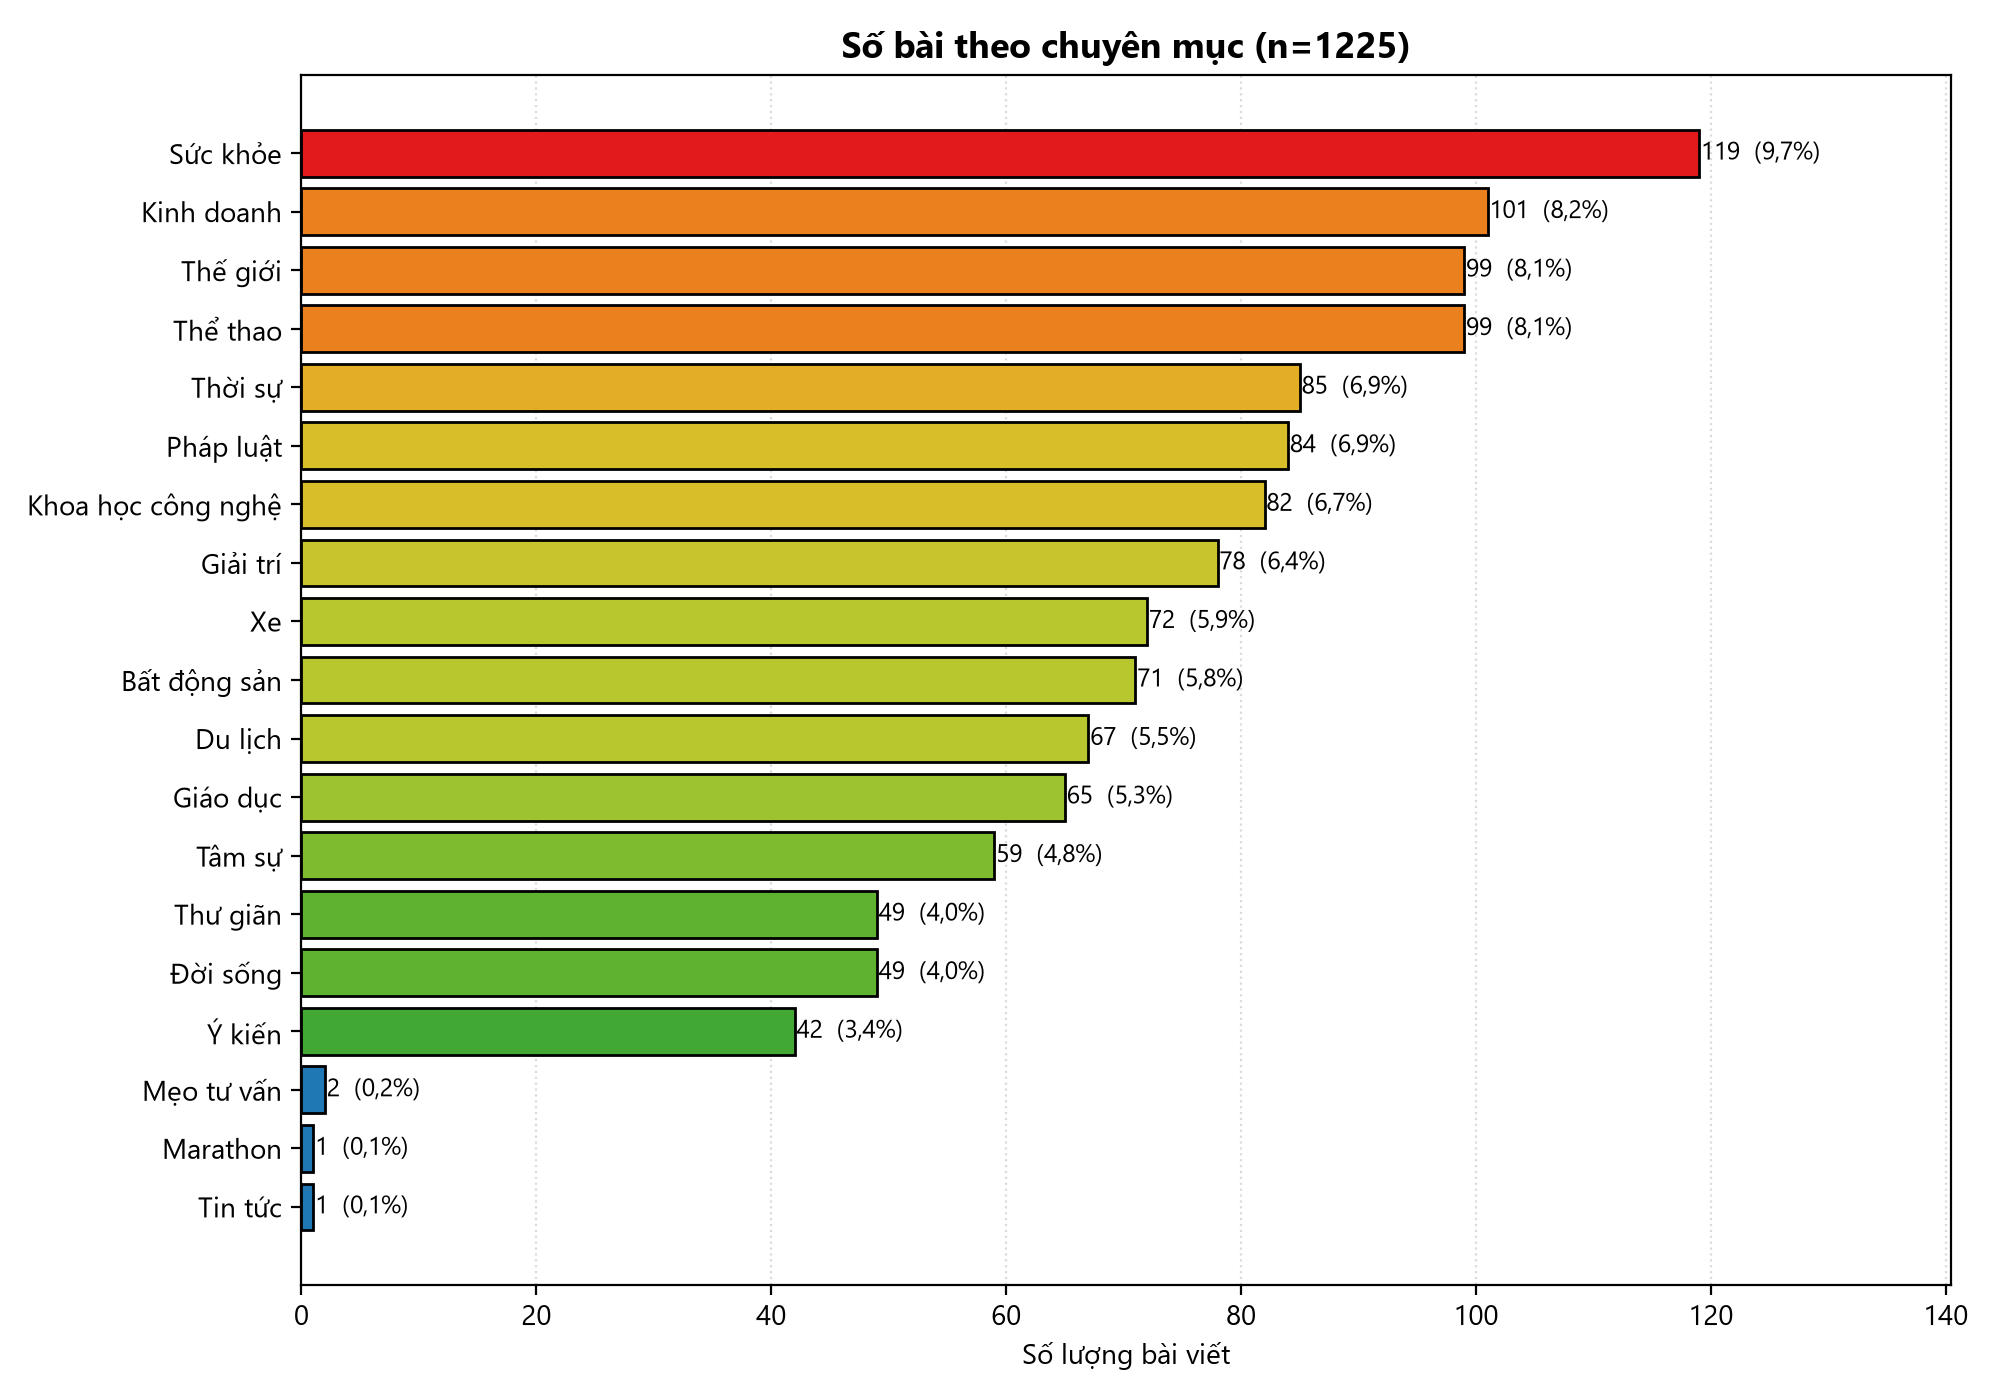


---
## 3.3. Biểu đồ 2: Tần số bài xuất bản theo 24 khung giờ & Phân tích hiện tượng đỉnh 0h (`ve_bieu_do_2`)

### Giải thích thiết kế mã nguồn
- Trích xuất trường giờ `hour = df['published_at'].dt.hour` và reindex đủ 24 khung giờ từ 0 đến 23 (bổ sung 0 cho các giờ không có bài).
- Vẽ biểu đồ cột đứng thể hiện nhịp điệu sinh hoạt và đăng tải thông tin của tòa soạn báo điện tử trong ngày.


In [ ]:
# Biểu đồ 2: Tần số bài xuất bản theo 24 khung giờ trong ngày
def ve_bieu_do_2(df):
    hour = df["hour"].dropna().astype(int)
    dem = hour.value_counts().reindex(range(24), fill_value=0)
    fig, ax = plt.subplots(figsize=(13, 6.5))
    bars = ax.bar(dem.index, dem.values, width=0.82, edgecolor="black", color=mau_theo_gia_tri(list(dem.values)))
    for b, v in zip(bars, dem.values):
        if v:
            ax.text(b.get_x() + b.get_width() / 2, v + 0.2, int(v), ha="center", va="bottom", fontsize=9)
    ax.set_title(f"Số bài xuất bản theo khung giờ (n={len(hour)})", fontsize=13, fontweight="bold")
    ax.set_xlabel("Khung giờ trong ngày")
    ax.set_ylabel("Số bài viết")
    ax.set_xticks(range(24), [f"{h}h" for h in range(24)])
    ax.tick_params(axis="x", labelsize=8)
    ax.set_xlim(-0.6, 23.6)
    ax.set_ylim(0, dem.max() * 1.18)
    ax.grid(axis="y", linestyle=":", alpha=0.45)
    ax.set_axisbelow(True)
    luu_anh(fig, "bieu_do_2_phan_bo_gio.png")


### Kết quả hiển thị Biểu đồ 2:
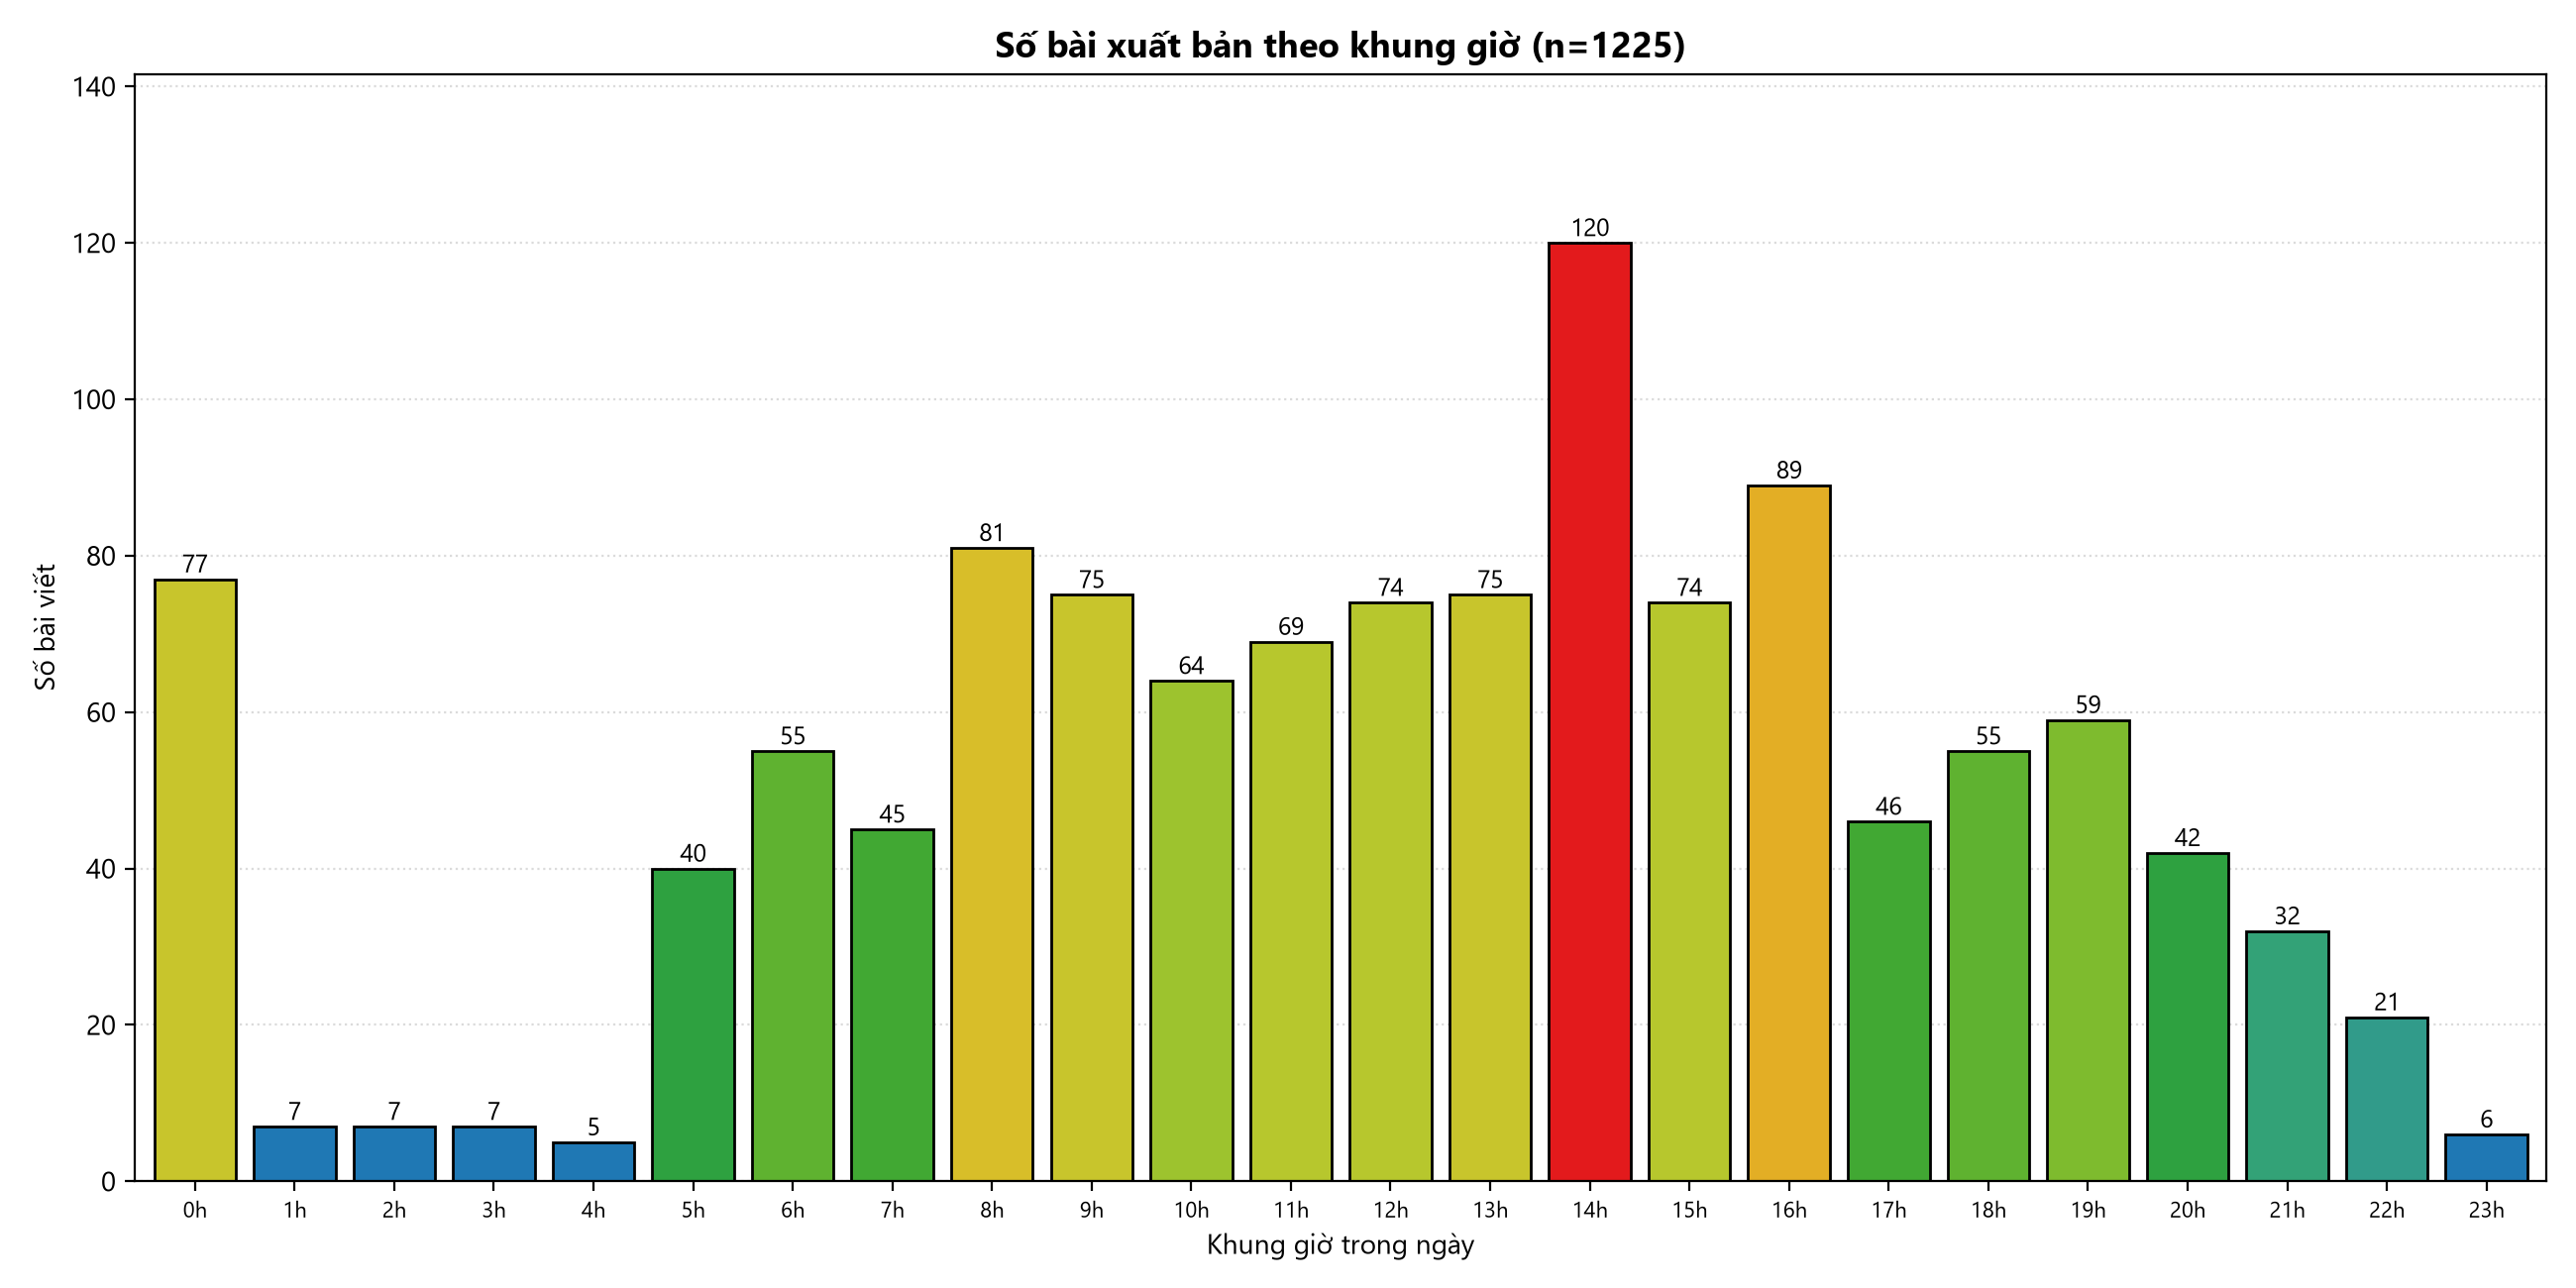

### Phân tích chuyên sâu: Vì sao số lượng bài viết đạt đỉnh vào khung 0h đêm?
Khi khảo sát chi tiết tệp dữ liệu, có **77 bài viết xuất hiện ở khung 0h**, trong đó có **45 bài mang mốc thời gian chính xác là `00:00:00`**:
1. **Nghiệp vụ tòa soạn (Scheduled Publishing):** Các bài phóng sự chuyên đề, góc nhìn, tin bài kinh doanh tổng hợp được biên tập xong từ chiều/tối hôm trước và được hệ thống CMS hẹn giờ tự động xuất bản ngay lúc **`00:00:00` đầu ngày mới** để đón đầu độc giả đọc báo vào sáng sớm (5h - 6h).
2. **Cơ chế bóc tách ngày giờ mặc định (Default Fallback):** Một số bài viết dạng chuyên đề trên web chỉ ghi ngày xuất bản mà không hiển thị giờ phút cụ thể; khi qua hàm chuẩn hóa `datetime.strptime(dm, "%d/%m/%Y")`, Python tự động gán mặc định giờ là `00:00:00`.


---
## 3.4. Biểu đồ 3: Cơ cấu tác giả bài viết (`ve_bieu_do_3`)

### Giải thích thiết kế mã nguồn
- Thống kê tỷ lệ bài viết do phóng viên trực thuộc tòa soạn VnExpress thực hiện so với bài viết có ghi nhận tác giả/cộng tác viên hoặc nguồn tin liên kết bên ngoài.
- Biểu đồ tròn (`pie chart`) với định dạng đường viền trắng tinh tế, nhãn tỷ lệ phần trăm phân cách bằng dấu phẩy theo chuẩn văn phong Việt Nam.


In [ ]:
# Biểu đồ 3: Cơ cấu tác giả bài viết (tròn: VnExpress vs Khác)
def ve_bieu_do_3(df):
    author = df["author"].fillna("VnExpress").str.strip()
    vne = int((author == "VnExpress").sum())
    vals = [vne, len(author) - vne]
    labels = ["VnExpress", "Các tác giả khác"]
    colors = ["#1f78b4", "#bdbdbd"]
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.pie(
        vals, labels=labels, colors=colors, startangle=90, counterclock=False, pctdistance=0.7,
        autopct=lambda p: f"{p:.1f}%".replace(".", ","),
        wedgeprops={"edgecolor": "white", "linewidth": 1.5}, textprops={"fontsize": 10}
    )
    ax.set_title(f"Cơ cấu tác giả bài viết (n={len(df)})", fontsize=13, fontweight="bold")
    luu_anh(fig, "bieu_do_3_tac_gia.png")


### Kết quả hiển thị Biểu đồ 3:
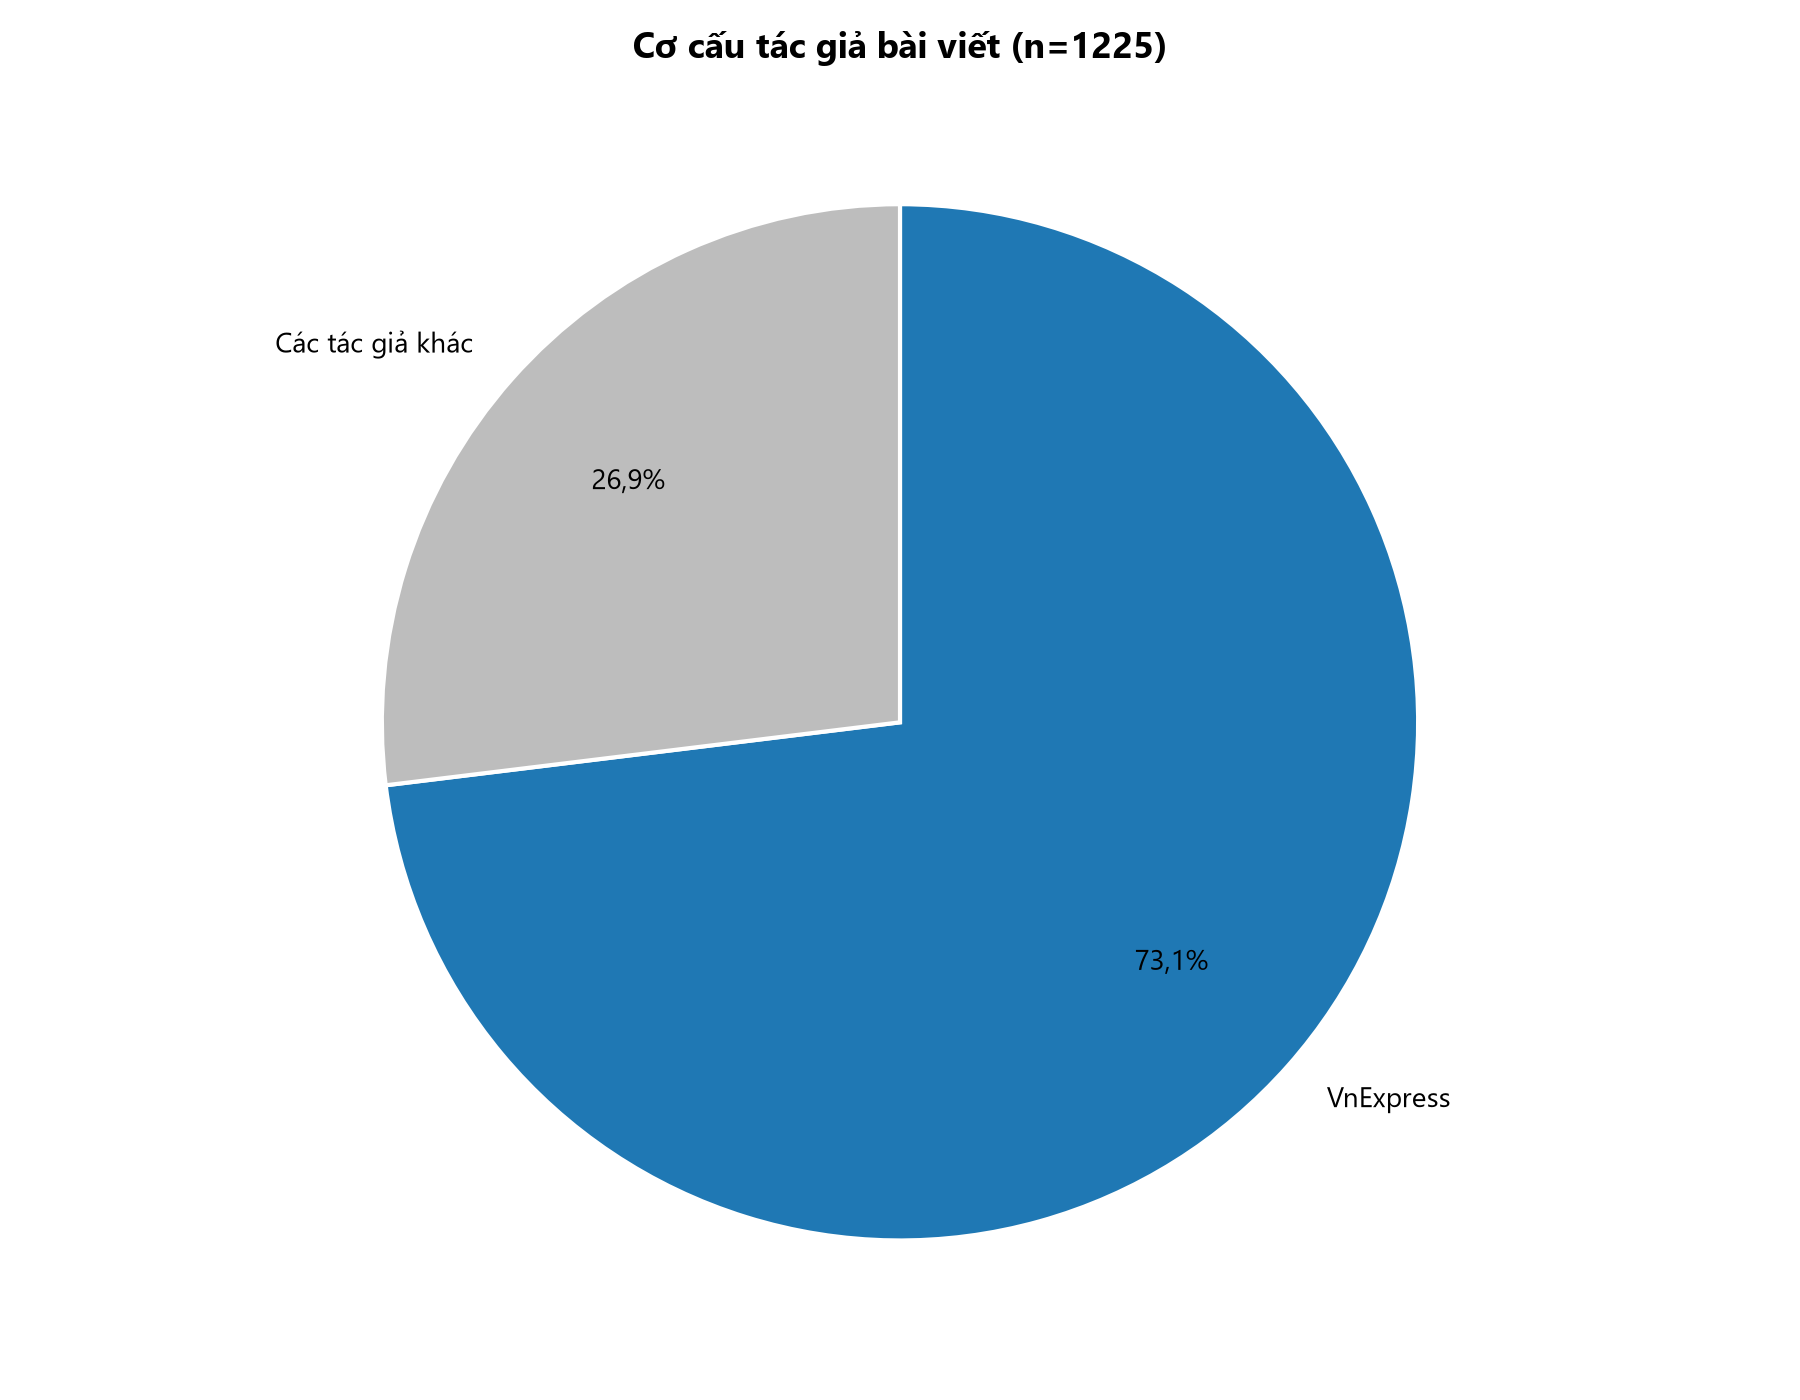


---
## 3.5. Biểu đồ 4: Bản đồ nhiệt mật độ bài viết ma trận lịch tháng (`ve_bieu_do_4`)

### Giải thích thiết kế mã nguồn
- Tự động lấy tháng và năm mới nhất trong tập dữ liệu, dựng ma trận lưới các tuần bằng `calendar.monthcalendar(year, month)`.
- Sử dụng các hình chữ nhật `plt.Rectangle` để dựng từng ô ngày trong tháng:
  - Ô ngày không thuộc tháng (giá trị 0): Tô xám nhạt (`#f4f4f4`).
  - Ô ngày không có bài viết: Tô xám trung tính (`#e8e8e8`).
  - Ô ngày có bài viết: Ánh xạ vào bảng màu `PALETTE`, màu càng đậm thể hiện ngày có lượng bài xuất bản càng nhiều.
- Tắt hoàn toàn đường trục tọa độ (`ax.axis('off')`) để tạo hiệu ứng Calendar Heatmap tương tự các báo cáo chuyên nghiệp của GitHub.


In [ ]:
# Biểu đồ 4: Bản đồ nhiệt 1 tháng dạng ma trận Lịch (Calendar Heatmap không trục)
def ve_bieu_do_4(df):
    valid_dates = df["published_at"].dropna()
    if valid_dates.empty:
        return

    latest = valid_dates.max()
    year, month = latest.year, latest.month
    month_data = df[(df["published_at"].dt.year == year) & (df["published_at"].dt.month == month)]
    day_counts = month_data["published_at"].dt.day.value_counts().to_dict()

    cal = calendar.monthcalendar(year, month)
    vmax = max(day_counts.values()) if day_counts else 1

    fig, ax = plt.subplots(figsize=(10, 7.5))
    weekday_names = ["Thứ 2", "Thứ 3", "Thứ 4", "Thứ 5", "Thứ 6", "Thứ 7", "Chủ Nhật"]
    for c, wname in enumerate(weekday_names):
        ax.text(c + 0.5, len(cal) + 0.25, wname, ha="center", va="center", fontsize=11, fontweight="bold", color="#333333")

    for r, week in enumerate(cal):
        for c, day in enumerate(week):
            y_pos = len(cal) - 1 - r
            if day == 0:
                rect = plt.Rectangle((c, y_pos), 1, 1, facecolor="#f4f4f4", edgecolor="white", linewidth=2.5)
                ax.add_patch(rect)
            else:
                val = day_counts.get(day, 0)
                color = PALETTE[int(round((val / vmax) * (len(PALETTE) - 1)))] if val > 0 else "#e8e8e8"
                rect = plt.Rectangle((c, y_pos), 1, 1, facecolor=color, edgecolor="white", linewidth=2.5)
                ax.add_patch(rect)
                txt = f"{day}\n({val})" if val > 0 else f"{day}"
                ax.text(c + 0.5, y_pos + 0.5, txt, ha="center", va="center", fontsize=11, fontweight="bold", color="white" if val > 0 else "#888888")

    ax.set_xlim(0, 7)
    ax.set_ylim(-0.2, len(cal) + 0.6)
    ax.axis("off")
    ax.set_title(f"Bản đồ nhiệt mật độ bài viết tháng {month}/{year} (n={len(month_data)})", fontsize=14, fontweight="bold", pad=15)
    luu_anh(fig, "bieu_do_4_nhiet_do_thang.png", rect=[0.05, 0.05, 0.95, 0.95])


### Kết quả hiển thị Biểu đồ 4:
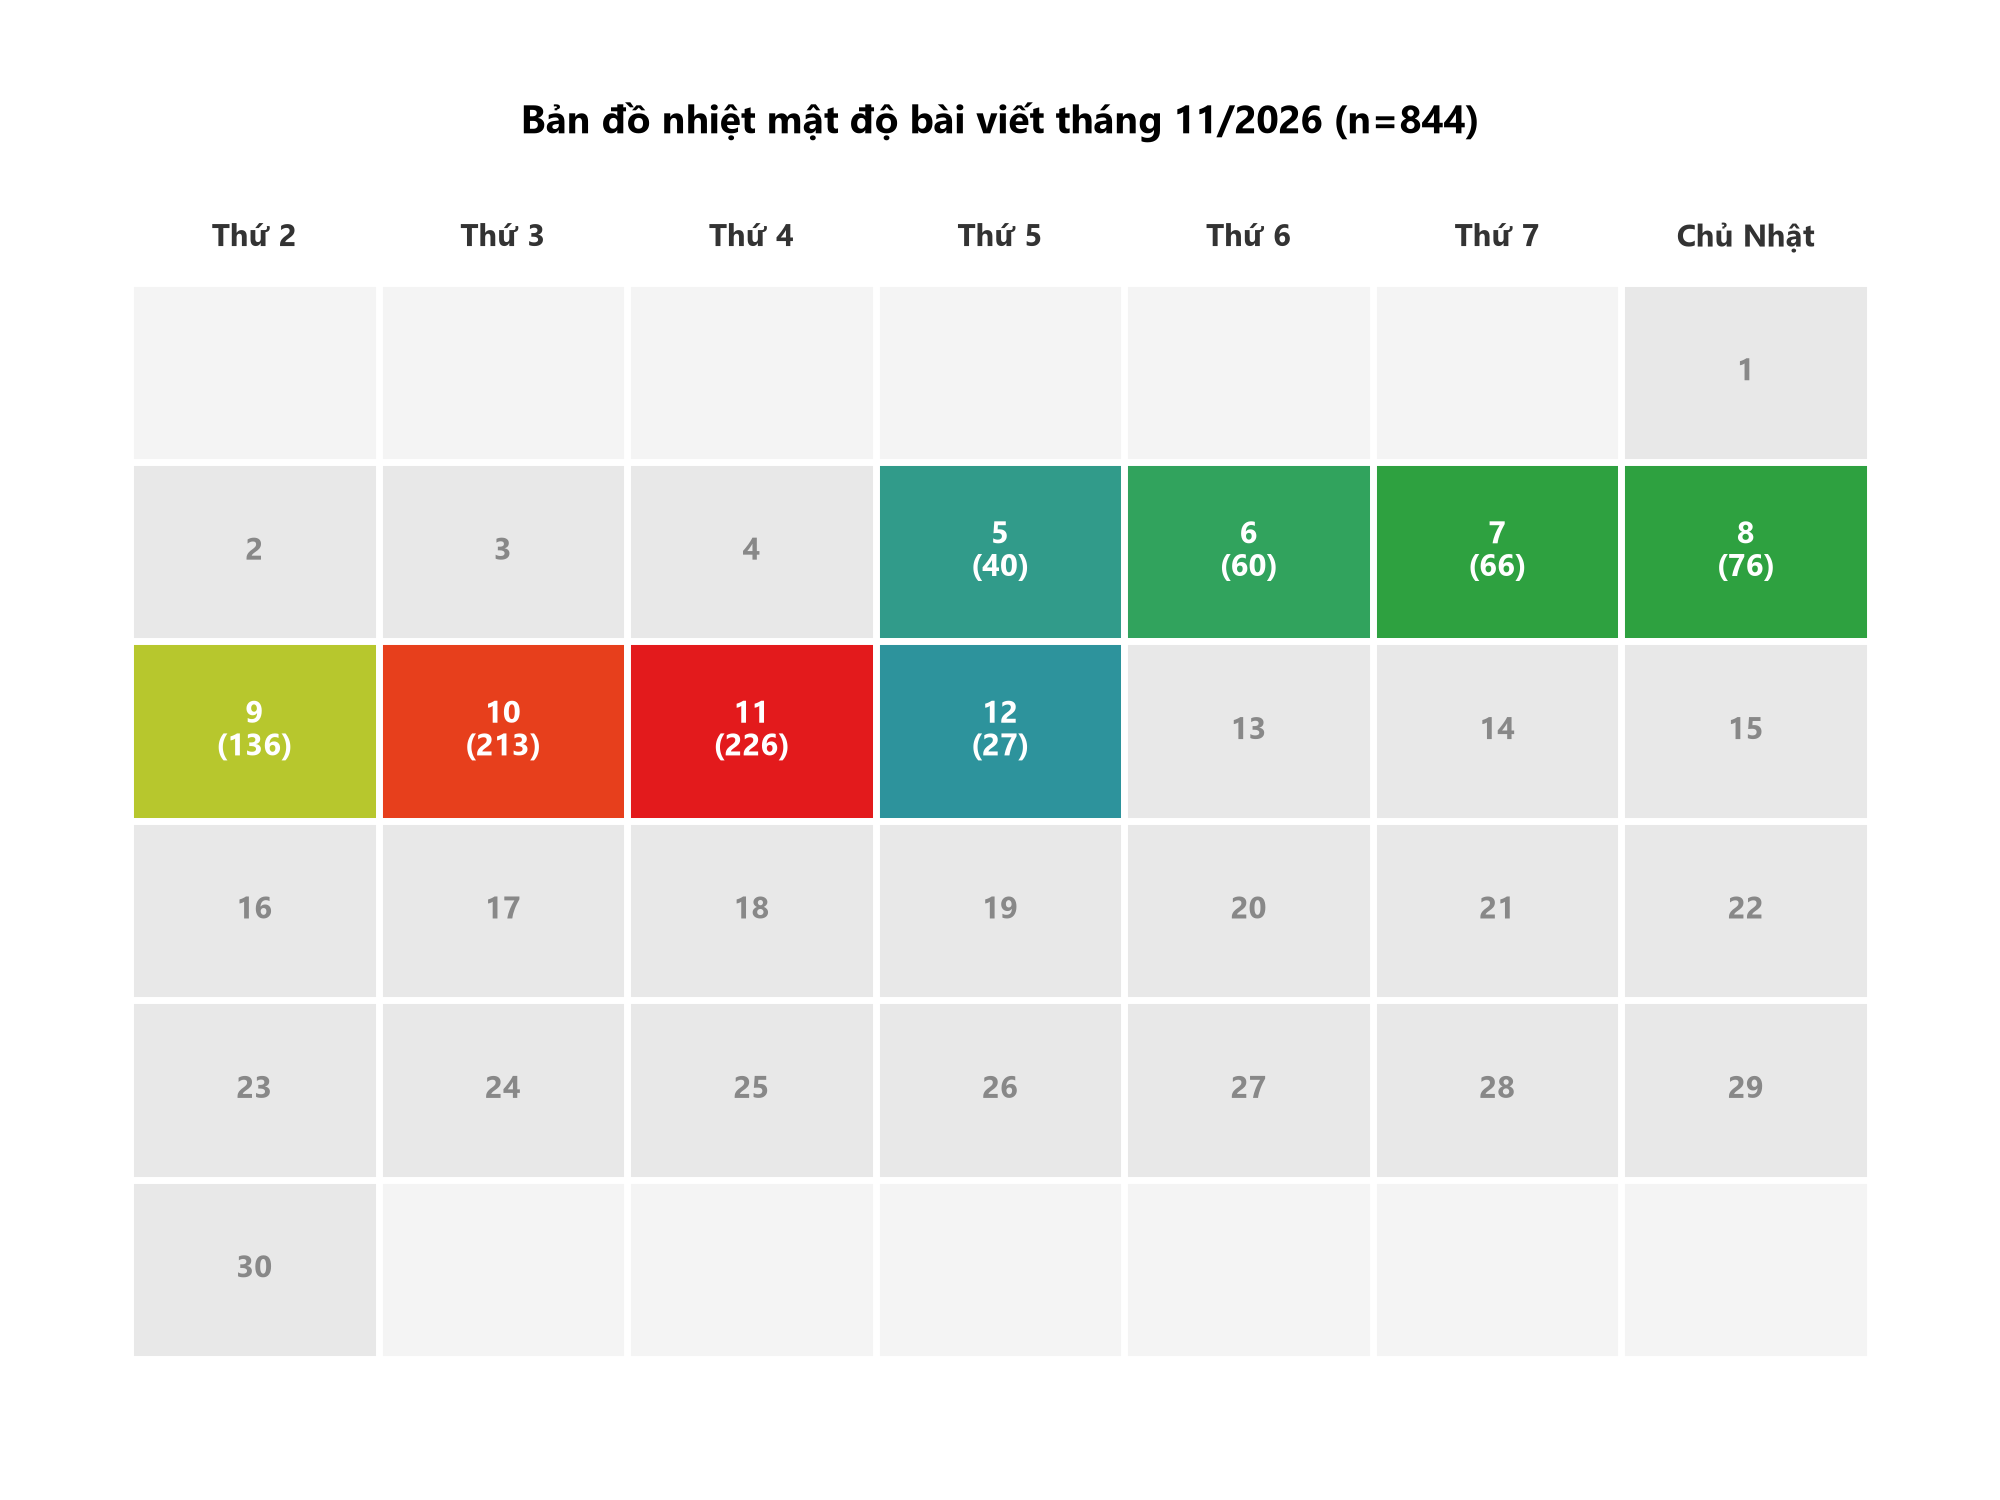


---
# PHẦN 4: HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH AI PHÂN LOẠI (`TrainClassifier.py`)

## Tổng quan Quy trình Khoa học Dữ liệu (Machine Learning Lifecycle)
- **Bài toán:** Phân loại văn bản đa lớp có giám sát (Multi-class Supervised Text Classification) nhằm tự động gán nhãn chuyên mục cho bài báo dựa trên ngữ cảnh tiêu đề, tóm tắt và nội dung.
- **Nguyên tắc cốt lõi:**
  1. Xử lý độc lập từ tệp dữ liệu đã làm sạch (`vnexpress_data.json`), không phụ thuộc CSDL.
  2. **Gate 1 - Toàn vẹn dữ liệu, chống rò rỉ (Data Leakage Protection):** Phân chia tập dữ liệu 80% train và 20% test hoàn toàn độc lập với kỹ thuật phân tầng (`Stratified Sampling`). Bộ vector hóa TF-IDF chỉ được `fit` trên tập train và chỉ `transform` trên tập test.
  3. **Gate 2 & 3 - Đánh giá chẩn đoán (Diagnostic Measures):** Đánh giá độ chính xác tổng thể, đo lường chi tiết F1-score/Precision/Recall, ma trận nhầm lẫn (Confusion Matrix) và phân tích tầm quan trọng của đặc trưng (`Feature Importance`).


### Khai báo thư viện và Cấu hình đường dẫn mô hình
- Sử dụng `scikit-learn` cho các thuật toán học máy, vector hóa và chỉ số đánh giá.
- Cấu hình đường dẫn lưu trữ mô hình (`category_classifier_model.joblib`), vectorizer (`tfidf_vectorizer.joblib`), ma trận nhầm lẫn (`confusion_matrix.png`) và số liệu đánh giá (`evaluation_metrics.json`).


In [ ]:
import os
import sys
import re
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
PROJECT_DIR = os.path.dirname(BASE_DIR)
MODEL_PATH = os.path.join(BASE_DIR, 'category_classifier_model.joblib')
VECTORIZER_PATH = os.path.join(BASE_DIR, 'tfidf_vectorizer.joblib')
CONFUSION_MATRIX_PATH = os.path.join(BASE_DIR, 'confusion_matrix.png')
METRICS_PATH = os.path.join(BASE_DIR, 'evaluation_metrics.json')


### Hàm 1: `load_crawler_data()` - Nạp dữ liệu đầu vào độc lập
- **Mục tiêu:** Nạp dữ liệu bài viết trực tiếp từ các file CSV hoặc JSON của crawler (ưu tiên `vnexpress_data.json` từ Phase 1).
- **Cơ chế linh hoạt:** Tự động tìm kiếm trong danh sách ứng viên `DATA_CANDIDATES`, hỗ trợ ghép nối thêm dữ liệu lịch sử hoặc dữ liệu mới nhất nếu có.
- **Kết quả:** Trả về đối tượng `pandas.DataFrame` sẵn sàng cho bước chuẩn bị dữ liệu.


In [ ]:
# Nạp dữ liệu bài viết trực tiếp từ file CSV hoặc JSON của crawler
def load_crawler_data():
    found_path = None
    for path in DATA_CANDIDATES:
        if os.path.exists(path):
            found_path = path
            break

    if not found_path:
        raise FileNotFoundError(
            f"[!] Không tìm thấy file dữ liệu từ Web crawler trong các vị trí: {DATA_CANDIDATES}"
        )

    print(f"[*] Nạp dữ liệu cào trực tiếp từ: {os.path.relpath(found_path, PROJECT_DIR)}")
    if found_path.endswith(".json"):
        with open(found_path, "r", encoding="utf-8") as f:
            data = json.load(f)
        df = pd.DataFrame(data)
    else:
        df = pd.read_csv(found_path)

    # Ghép thêm dữ liệu đợt cào mới nhất nếu đang dùng tập historical
    latest_csv = os.path.join(PROJECT_DIR, "Web crawler", "vnexpress_data.csv")
    if found_path != latest_csv and os.path.exists(latest_csv):
        df_latest = pd.read_csv(latest_csv)
        df = pd.concat([df, df_latest], ignore_index=True)
        if "article_id" in df.columns:
            df = df.drop_duplicates(subset=["article_id"], keep="last")

    return df


### Hàm 2: `clean_vietnamese_text(text)` - Tiền xử lý NLP văn bản tiếng Việt
- **Mục tiêu:** Chuẩn hóa chuỗi văn bản thô, loại bỏ các thành phần gây nhiễu trước khi vector hóa.
- **Các bước làm sạch:**
  1. Chuyển toàn bộ văn bản về chữ thường (`.lower()`).
  2. Loại bỏ các đường dẫn URL (`https?://\S+|www\.\S+`).
  3. Loại bỏ ký tự đặc biệt, dấu câu, thẻ HTML thừa bằng Regex nhưng **giữ trọn vẹn bộ ký tự nguyên âm tiếng Việt có dấu** (`àáạảãâ...đ`).
  4. Chuẩn hóa các khoảng trắng thừa liên tiếp thành một dấu cách duy nhất.


In [ ]:
# Làm sạch văn bản tiếng Việt: chữ thường, bỏ url, ký tự lạ và chuẩn hóa khoảng trắng
def clean_vietnamese_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)  # bỏ url
    text = re.sub(r"[^\w\sàáạảãâầấậẩẫăằắặẳẵèéẹẻẽêềếệểễìíịỉĩòóọỏõôồốộổỗơờớợởỡùúụủũưừứựửữỳýỵỷỹđ]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


### Hàm 3: `preprocess_dataset(df)` - Chuẩn hóa và chuẩn bị tập dữ liệu huấn luyện
- **Ghép nối đặc trưng ngữ cảnh:** Ghép `title + description + content` thành một chuỗi đại diện duy nhất `clean_text` để cung cấp đầy đủ thông tin ngữ nghĩa cho mô hình học máy.
- **Lọc dữ liệu không hợp lệ:**
  1. Loại bỏ các bài viết có độ dài chuỗi sạch `< 20` ký tự.
  2. Loại bỏ các bài viết thiếu chuyên mục hoặc thuộc nhóm nhãn không xác định (`'Khác'`).
  3. **Lọc tần suất lớp:** Chỉ giữ lại các chuyên mục có số lượng bài viết tối thiểu `>= 4` để đảm bảo khi phân chia `train_test_split(stratify=y)` không bị lỗi thiếu mẫu ở từng lớp.


In [ ]:
# Chuẩn bị dữ liệu: ghép text, làm sạch và lọc các chuyên mục đủ số mẫu huấn luyện
def preprocess_dataset(df):
    titles = df["title"].fillna("")
    descriptions = df["description"].fillna("")
    contents = df["content"].fillna("")

    full_text = titles + " " + descriptions + " " + contents
    df["clean_text"] = full_text.apply(clean_vietnamese_text)

    # Lọc bỏ các bài không có nội dung hoặc thuộc chuyên mục 'Khác'
    df = df[df["clean_text"].str.strip().str.len() > 20].copy()
    if "category" in df.columns:
        df = df[df["category"].notna()].copy()
        df = df[df["category"].str.strip() != "Khác"].copy()

    # Lọc các chuyên mục có số mẫu tối thiểu >= 4 để đảm bảo phân chia train/test hợp lệ
    counts = df["category"].value_counts()
    valid_categories = counts[counts >= 4].index
    df = df[df["category"].isin(valid_categories)].copy()

    print(f"[*] Dữ liệu sau chuẩn hóa: {len(df)} bài báo thuộc {len(valid_categories)} chuyên mục hợp lệ.")
    return df


### Hàm 4: `plot_confusion_matrix(cm, labels, save_path)` - Trực quan hóa Ma trận Nhầm lẫn
- **Mục tiêu:** Trực quan hóa kết quả phân loại trên tập kiểm tra bằng bản đồ nhiệt (Heatmap) 2 chiều.
- **Thiết kế đồ họa:**
  - Trục tung ($Y$): Chuyên mục thực tế (`True Label`).
  - Trục hoành ($X$): Chuyên mục dự đoán (`Predicted Label`).
  - Tự động đảo màu chữ số (trắng/đen) dựa theo ngưỡng `thresh = cm.max() / 2.0` để tối ưu độ tương phản thị giác.


In [ ]:
# Vẽ ma trận nhầm lẫn (Confusion Matrix) dạng Heatmap và lưu vào file ảnh
def plot_confusion_matrix(cm, labels, save_path):
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=labels,
        yticklabels=labels,
        title="Ma trận nhầm lẫn (Confusion Matrix) - Phân loại chuyên mục",
        ylabel="Chuyên mục thực tế (True Label)",
        xlabel="Chuyên mục dự đoán (Predicted Label)",
    )

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    # Điền giá trị vào từng ô
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            val = cm[i, j]
            ax.text(
                j, i, format(val, "d") if val > 0 else "0",
                ha="center", va="center",
                color="white" if val > thresh else "black",
                fontsize=8, fontweight="bold" if val > 0 else "normal"
            )

    fig.tight_layout()
    fig.savefig(save_path, dpi=200, facecolor="white")
    plt.close(fig)
    print(f"[+] Đã lưu biểu đồ ma trận nhầm lẫn tại: {os.path.relpath(save_path, PROJECT_DIR)}")


### Kết quả hiển thị Ma trận Nhầm lẫn (Confusion Matrix Heatmap):
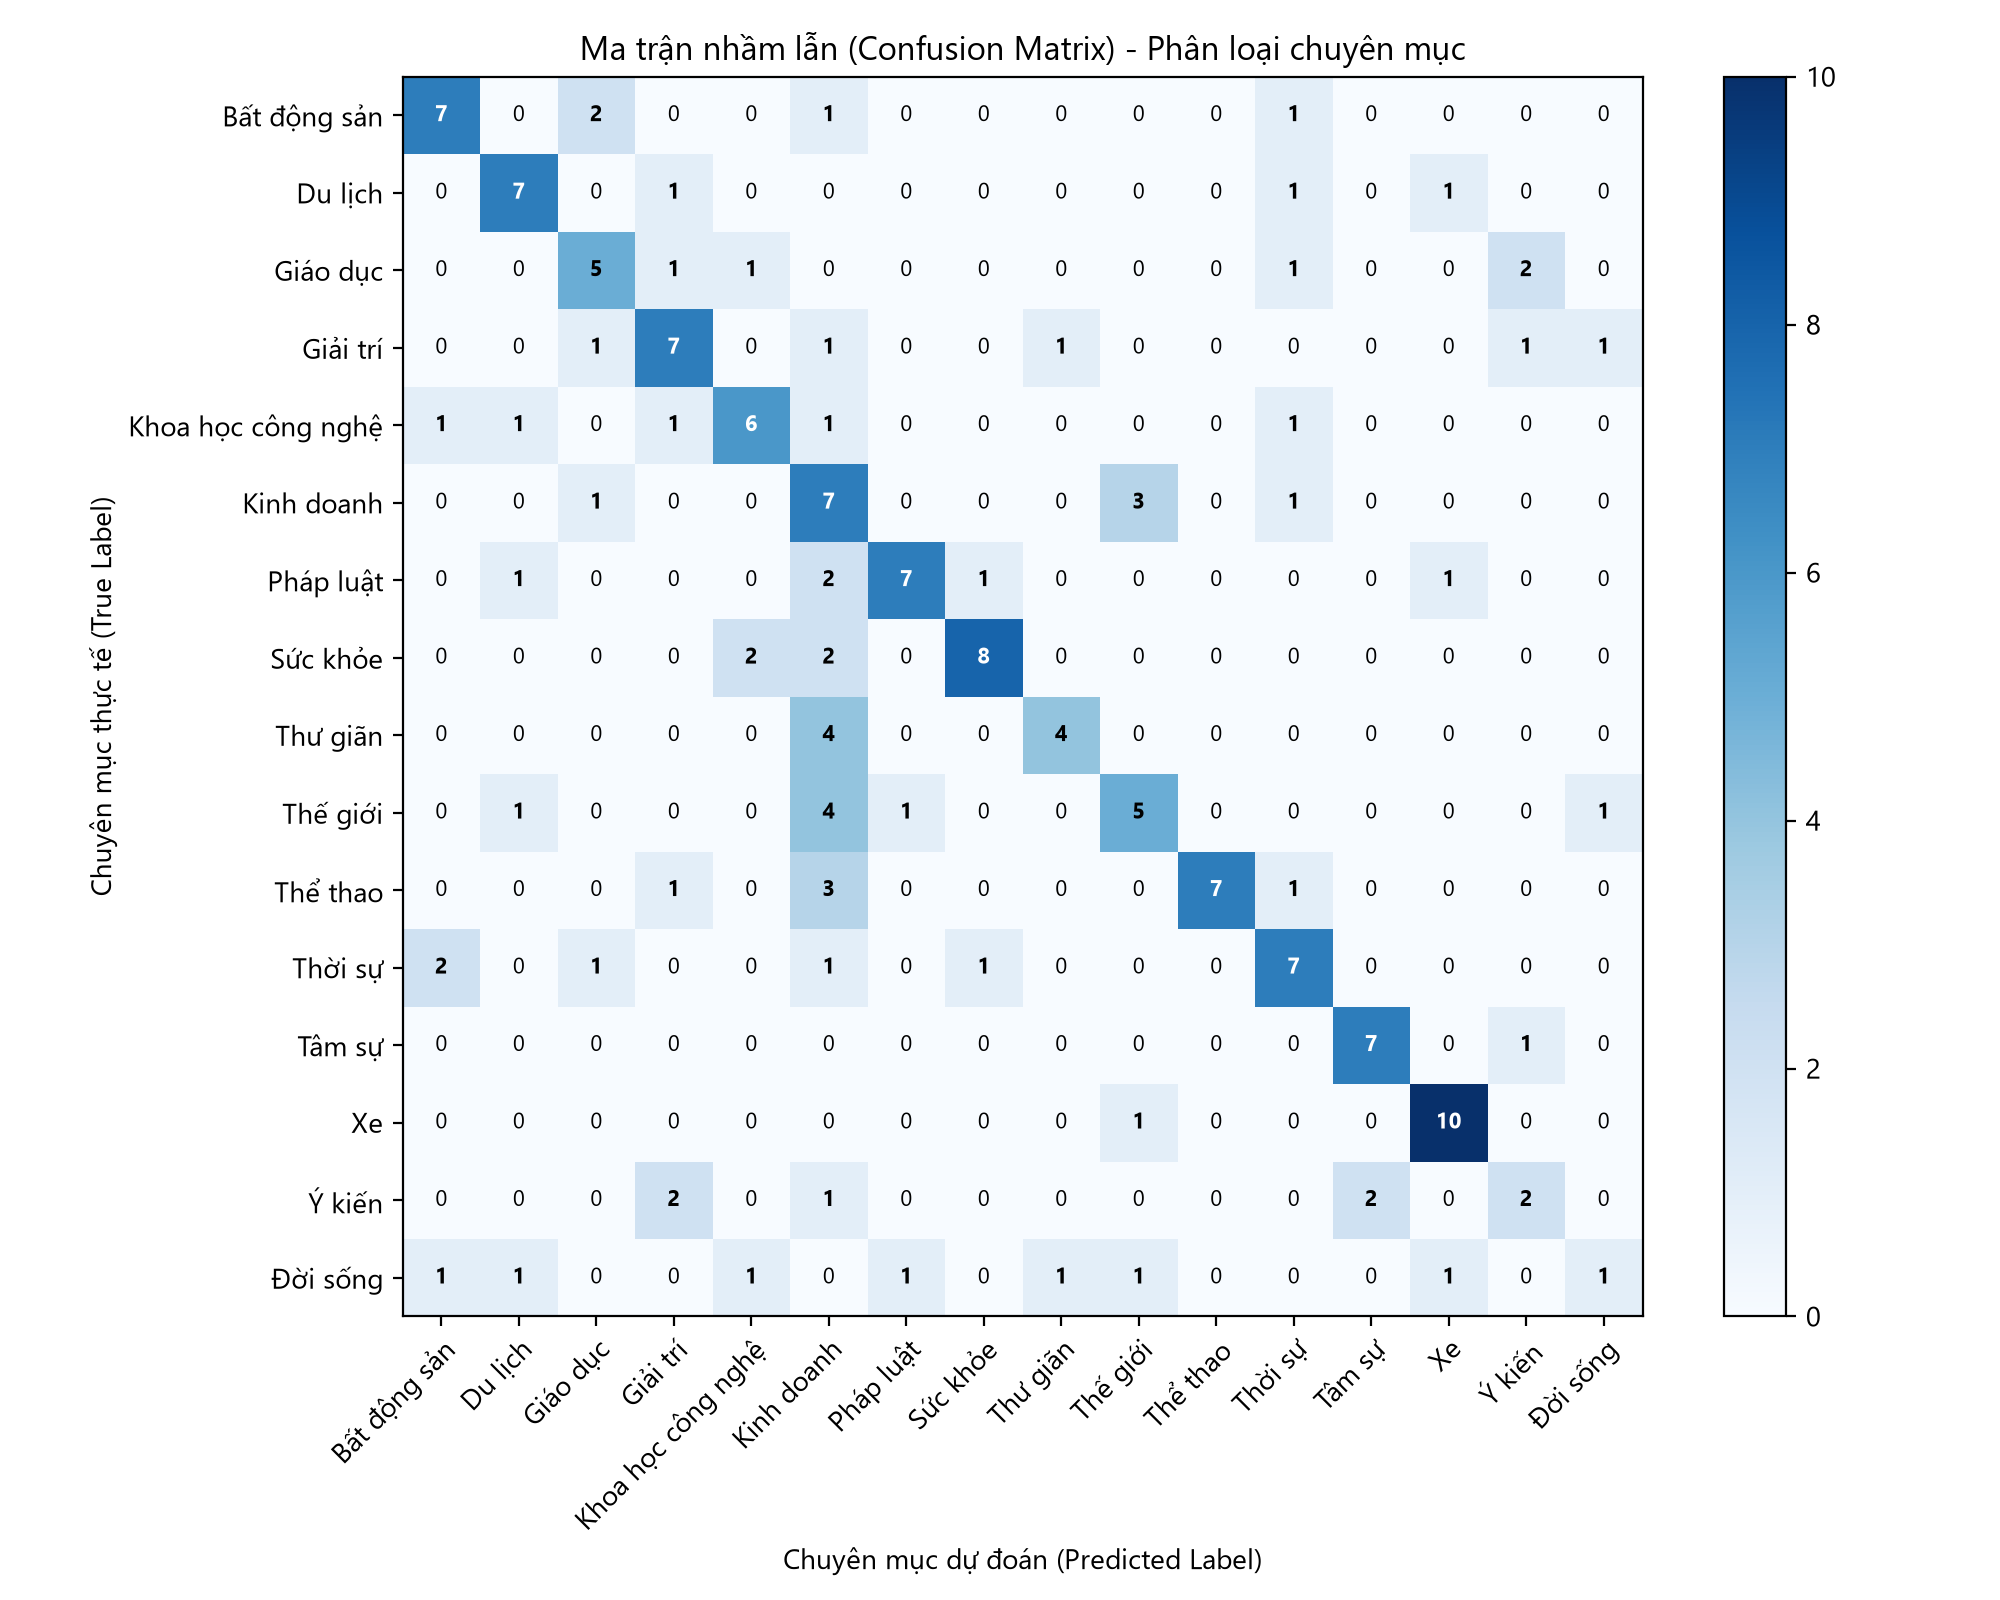

#### Đánh giá chẩn đoán từ Ma trận Nhầm lẫn:
1. **Đường chéo chính (True Positives):** Tập trung đa số các mẫu dự đoán đúng của từng chuyên mục (thể hiện bằng các ô màu xanh đậm với số lượng lớn).
2. **Các điểm ngoài đường chéo (False Positives / False Negatives):** Phản ánh các trường hợp mô hình bị nhầm lẫn ngữ nghĩa giữa các nhóm chủ đề có từ khóa tương đồng (ví dụ: *Bất động sản* với *Kinh doanh*, *Thời sự* với *Pháp luật*).


### Hàm 5: `train_and_evaluate()` - Huấn luyện, Đánh giá và Xuất mô hình
- **Quy trình thực thi:**
  1. Phân chia Train/Test 80/20 với `random_state=42` và `stratify=y` (chống rò rỉ dữ liệu).
  2. Trích xuất đặc trưng với `TfidfVectorizer(max_features=4000, ngram_range=(1, 2), sublinear_tf=True)`.
  3. Huấn luyện mô hình chủ đạo **Cây quyết định (Decision Tree)**: cấu hình `max_depth=25`, `min_samples_split=4` để kiểm soát hiện tượng Overfitting.
  4. Huấn luyện mô hình đối chứng **Multinomial Naive Bayes** (`alpha=0.1`).
  5. Đánh giá chẩn đoán bằng `classification_report` và gọi `plot_confusion_matrix()`.
  6. Trích xuất **Top 15 đặc trưng (từ khóa) có trọng số Gini cao nhất** (`Feature Importance`).
  7. Lưu mô hình vào tệp `.joblib` và chỉ số đánh giá vào `evaluation_metrics.json`.


In [ ]:
# Huấn luyện mô hình Decision Tree và Naive Bayes, đánh giá và lưu kết quả
def train_and_evaluate():
    print("=" * 65)
    print(" GIAI ĐOẠN 7 & 8: HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH AI PHÂN LOẠI ")
    print("=" * 65)

    # 1. Nạp và chuẩn hóa dữ liệu
    df = load_crawler_data()
    df = preprocess_dataset(df)

    X = df["clean_text"]
    y = df["category"]

    # 2. Phân chia Train/Test độc lập (Gate 1 - Toàn vẹn dữ liệu, chống rò rỉ)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    print(f"[*] Phân chia tập dữ liệu: {len(X_train)} bài train (80%) | {len(X_test)} bài test (20%)")

    # 3. Trích xuất đặc trưng văn bản bằng TF-IDF
    vectorizer = TfidfVectorizer(
        max_features=4000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )
    X_train_vec = vectorizer.fit_transform(X_train)
    X_test_vec = vectorizer.transform(X_test)

    # 4. Huấn luyện mô hình Cây quyết định (Decision Tree)
    dt_model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=25,
        min_samples_split=4,
        random_state=42
    )
    dt_model.fit(X_train_vec, y_train)

    # Huấn luyện mô hình đối chứng Naive Bayes
    nb_model = MultinomialNB(alpha=0.1)
    nb_model.fit(X_train_vec, y_train)

    # 5. Đánh giá chẩn đoán trên tập kiểm tra độc lập
    dt_pred = dt_model.predict(X_test_vec)
    nb_pred = nb_model.predict(X_test_vec)
    dt_acc = accuracy_score(y_test, dt_pred)
    nb_acc = accuracy_score(y_test, nb_pred)

    print(f"Độ chính xác Decision Tree: {dt_acc * 100:.2f}%")
    print(f"Độ chính xác Naive Bayes:    {nb_acc * 100:.2f}%")

    # 6. Vẽ và lưu Ma trận nhầm lẫn
    labels = sorted(list(y.unique()))
    cm = confusion_matrix(y_test, dt_pred, labels=labels)
    plot_confusion_matrix(cm, labels, CONFUSION_MATRIX_PATH)

    # 7. Trích xuất Top từ khóa đặc trưng quan trọng
    importances = dt_model.feature_importances_
    feature_names = np.array(vectorizer.get_feature_names_out())
    top_indices = np.argsort(importances)[::-1][:15]

    # 8. Lưu trữ mô hình và bộ vector hóa
    joblib.dump(dt_model, MODEL_PATH)
    joblib.dump(vectorizer, VECTORIZER_PATH)
    return dt_model, vectorizer


### Hàm 6: `predict_article_category(title, description, content)` - Ứng dụng triển khai mô hình (Deployment)
- **Mục tiêu:** Nhận thông tin của một bài báo hoàn toàn mới (chưa dán nhãn).
- **Quy trình:** Nạp trực tiếp mô hình và vectorizer đã lưu trữ (`.joblib`), làm sạch văn bản, chuyển thành vector TF-IDF và đưa ra dự đoán chuyên mục tức thì.


In [ ]:
# Dự đoán chuyên mục cho một bài báo mới dựa trên mô hình và TF-IDF đã lưu
def predict_article_category(title, description, content):
    if not os.path.exists(MODEL_PATH) or not os.path.exists(VECTORIZER_PATH):
        raise FileNotFoundError("Mô hình chưa được huấn luyện. Hãy chạy train_and_evaluate() trước.")

    model = joblib.load(MODEL_PATH)
    vec = joblib.load(VECTORIZER_PATH)

    raw_text = f"{title} {description} {content}"
    clean = clean_vietnamese_text(raw_text)
    x_vec = vec.transform([clean])
    predicted_cat = model.predict(x_vec)[0]
    return predicted_cat


---
# PHẦN 5: ĐIỀU PHỐI TỰ ĐỘNG HÓA PIPELINE (`Automation.py`)

### Mục tiêu thiết kế
Tự động hóa vận hành khép kín toàn bộ chuỗi 5 bước của dự án chỉ trong một lần chạy duy nhất:
- Nếu có bất kỳ bước nào lỗi (mã thoát khác 0), chuỗi dừng ngay lập tức và ghi nhật ký kiểm toán vào `scheduler.log`.
- Đảm bảo dữ liệu được thu thập, mô hình AI được tái huấn luyện và biểu đồ EDA được làm mới hoàn chỉnh.


In [ ]:
STEPS = [
    ("Step 1: Raw Crawler", os.path.join(BASE_DIR, "Phase 1 - Data crawl & Post process + Quick report", "Step1_RawCrawler.py")),
    ("Step 2: Data Filter", os.path.join(BASE_DIR, "Phase 1 - Data crawl & Post process + Quick report", "Step2_DataFilter.py")),
    ("Step 3: Train model", os.path.join(BASE_DIR, "Train model", "TrainClassifier.py")),
    ("Step 4: SQL importer", os.path.join(BASE_DIR, "Phase 2 - Import data to SQL", "SQLimporter.py")),
    ("Step 5: EDA + charts", os.path.join(BASE_DIR, "Phase 3 - EDA", "Charts.py")),
]

# Ghi một dòng thông điệp kèm timestamp hiện tại vào tệp nhật ký scheduler.log
def ghi_log(noi_dung):
    with open(LOG_PATH, "a", encoding="utf-8") as f:
        f.write(f"[{datetime.now():%Y-%m-%d %H:%M:%S}] {noi_dung}\n")

# Chạy một script con bằng đúng Python đang dùng, dừng chuỗi nếu thất bại
def chay_buoc(ten, duong_dan):
    print(f"\n[{datetime.now():%d/%m/%Y %H:%M:%S}] Bắt đầu {ten}")
    ket_qua = subprocess.run([sys.executable, duong_dan], cwd=BASE_DIR)
    if ket_qua.returncode != 0:
        print(f"[!] {ten} thất bại (mã {ket_qua.returncode}), dừng chuỗi lần này.")
        ghi_log(f"{ten} thất bại (mã {ket_qua.returncode})")
        return False
    return True

# Chạy lần lượt 5 bước của pipeline, dừng ngay khi một bước gặp lỗi
def chay_chuoi():
    ghi_log("Bắt đầu chuỗi 5 bước")
    for ten, duong_dan in STEPS:
        if not chay_buoc(ten, duong_dan):
            return False
    ghi_log("Hoàn tất chuỗi 5 bước")
    return True

# Điều phối chạy trọn vẹn một lần chuỗi 5 bước pipeline của dự án
def main():
    print("Bắt đầu chạy chuỗi 5 bước (Raw Crawl -> Filter -> AI Classifier -> SQL -> EDA)...")
    thanh_cong = chay_chuoi()
    if thanh_cong:
        print("\n[+] Đã hoàn thành xuất sắc toàn bộ chuỗi 5 bước của hệ thống!")
    else:
        print("\n[!] Chuỗi pipeline đã dừng do có bước gặp lỗi.")
